##Problem 2

Part b

Define functions for calculations

In [ ]:
import numpy as np
import scipy.special as special
from scipy.integrate import quad
import math

# constants
a_0       = 5.29177e-11
h_J       = 6.62607e-34      # J s  (for the A formula)
h_eV      = 4.135667e-15     # eV s (for nu_0)
e         = 1.602177e-19
c         = 2.99792e8
epsilon_0 = 8.85419e-12

def nu_0(n_i, n_j):
    return (13.6057 / h_eV) * (1/n_i**2 - 1/n_j**2)      # Hz

# radial function, r in units of a_0 (conversion from Homework 2, checked with Claude)
def R_nl(r, n, l):
    if l > n - 1 or l < 0: #Conditional used help from Gemini
        return 0.0 #forbidden!
    pref = np.sqrt(4*math.factorial(n-l-1) / (n**4 * math.factorial(n+l)))
    return pref * np.exp(-r/n) * (2*r/n)**l * special.genlaguerre(n-l-1, 2*l+1)(2*r/n)

# theta part of Y_lm: evaluate Y at phi = 0 (real)
# idea from https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.sph_harm_y.html$0
def Theta(theta, l, m):
    return special.sph_harm_y(l, m, theta, 0.0).real

# r and theta integrals only (no phi included)
def radial_integral(n_i, l_i, n_j, l_j):
    if l_i > n_i - 1 or l_j > n_j - 1: #Conditional used help from Gemini
        return 0.0 #forbidden!
    return quad(lambda r: R_nl(r, n_i, l_i) * R_nl(r, n_j, l_j) * r**3, #we ignore the 1/a_0 since r is already in units of a_0
                0, np.inf)[0]

def M_plus(n_i, l_i, m_i, n_j, l_j, m_j):
    I_r = radial_integral(n_i, l_i, n_j, l_j)
    I_t = quad(lambda t: Theta(t, l_i, m_i) * Theta(t, l_j, m_j) * np.sin(t)**2,
               0, np.pi)[0]
    return 0.5 * I_r * I_t

def M_minus(n_i, l_i, m_i, n_j, l_j, m_j):
    return M_plus(n_i, l_i, m_i, n_j, l_j, m_j)

def M_z(n_i, l_i, m_i, n_j, l_j, m_j):
    I_r = radial_integral(n_i, l_i, n_j, l_j)
    I_t = quad(lambda t: Theta(t, l_i, m_i) * Theta(t, l_j, m_j)
                         * np.cos(t) * np.sin(t), 0, np.pi)[0]
    return I_r * I_t

# Fourier trick: always return (M+, M-, Mz)
def apply_phi(m_i, m_j, Mp, Mm, Mz):
    delta_m = m_i - m_j
    if delta_m == 0:
      return 0.0, 0.0, 2*np.pi*Mz
    elif delta_m == -1:
      return 2*np.pi*Mp, 0.0, 0.0
    elif delta_m == 1:
      return 0.0, 2*np.pi*Mm, 0.0
    else:
      return 0.0, 0.0, 0.0      # forbidden!

def mod_M(Mp, Mm, Mz):
    return 2*abs(Mp)**2 + 2*abs(Mm)**2 + abs(Mz)**2

def A_ji(n_i, l_i, m_i, n_j, l_j, m_j):
    if l_i > n_i - 1 or l_j > n_j - 1 or abs(m_i) > l_i or abs(m_j) > l_j:
        return 0.0 # Return 0 for physically impossible states
    Mp = M_plus(n_i, l_i, m_i, n_j, l_j, m_j)
    Mm = M_minus(n_i, l_i, m_i, n_j, l_j, m_j)
    Mz = M_z(n_i, l_i, m_i, n_j, l_j, m_j)
    Mp, Mm, Mz = apply_phi(m_i, m_j, Mp, Mm, Mz)
    M2 = mod_M(Mp, Mm, Mz)
    nu = nu_0(n_i, n_j)
    return 16*np.pi**3 * nu**3 * e**2 * a_0**2 / (3*epsilon_0 * h_J * c**3) * M2

Perform calculations for identical upper and lower levels!

In [ ]:
import numpy as np
import scipy.special as special
from scipy.integrate import quad
import math
import pandas as pd

n_vals = []
l_vals = []
m_i_vals = []
m_j_vals = []
A_ji_vals = []
m_forbiddens = []

# Print out tests for identical upper and lower levels (n stays the same, l stays the same
# m_i = -1, 0, 1 and m_j = -1, 0, 1)
# The principal quantum number n must start at 1 (n = 1, 2, 3)
#Note: Gemini was used for the logic to help in building this table/dataframe
for n in range(1, 4):
  for l in range(0, n):
    for m_i in range(-1, 2):
      for m_j in range(-1, 2):
        val = A_ji(n, l, m_i, n, l, m_j)
        # Determine if this state is forbidden
        m_is_forbidden = ""
        if abs(m_i) > l or abs(m_j) > l:
          continue
        elif np.abs(m_i - m_j) > 1:
          m_is_forbidden = "Yes"
        else:
          m_is_forbidden = "No"

        # Append values to lists to build the DataFrame
        n_vals.append(n)
        l_vals.append(l)
        m_i_vals.append(m_i)
        m_j_vals.append(m_j)
        A_ji_vals.append(val)
        m_forbiddens.append(m_is_forbidden)

# Build the DataFrame
df = pd.DataFrame({
    r"$n$": n_vals,
    r"$\ell$": l_vals,
    r"$m_i$": m_i_vals,
    r"$m_j$": m_j_vals,
    r"$A_{ji}$": A_ji_vals,
    r"$\Delta m$ Forbidden?": m_forbiddens
})

latex_code = df.to_latex(
    index=False,
    float_format="%.1f", # Changed format to scientific notation
    label="tab:prob2partb",
    column_format="cccccc",
    escape=False,
    longtable=True
)

print(latex_code)

\begin{longtable}{cccccc}
\label{tab:prob2partb} \\
\toprule
$n$ & $\ell$ & $m_i$ & $m_j$ & $A_{ji}$ & $\Delta m$ Forbidden? \\
\midrule
\endfirsthead
\toprule
$n$ & $\ell$ & $m_i$ & $m_j$ & $A_{ji}$ & $\Delta m$ Forbidden? \\
\midrule
\endhead
\midrule
\multicolumn{6}{r}{Continued on next page} \\
\midrule
\endfoot
\bottomrule
\endlastfoot
1 & 0 & 0 & 0 & 0.0 & No \\
2 & 0 & 0 & 0 & 0.0 & No \\
2 & 1 & -1 & -1 & 0.0 & No \\
2 & 1 & -1 & 0 & 0.0 & No \\
2 & 1 & -1 & 1 & 0.0 & Yes \\
2 & 1 & 0 & -1 & 0.0 & No \\
2 & 1 & 0 & 0 & 0.0 & No \\
2 & 1 & 0 & 1 & 0.0 & No \\
2 & 1 & 1 & -1 & 0.0 & Yes \\
2 & 1 & 1 & 0 & 0.0 & No \\
2 & 1 & 1 & 1 & 0.0 & No \\
3 & 0 & 0 & 0 & 0.0 & No \\
3 & 1 & -1 & -1 & 0.0 & No \\
3 & 1 & -1 & 0 & 0.0 & No \\
3 & 1 & -1 & 1 & 0.0 & Yes \\
3 & 1 & 0 & -1 & 0.0 & No \\
3 & 1 & 0 & 0 & 0.0 & No \\
3 & 1 & 0 & 1 & 0.0 & No \\
3 & 1 & 1 & -1 & 0.0 & Yes \\
3 & 1 & 1 & 0 & 0.0 & No \\
3 & 1 & 1 & 1 & 0.0 & No \\
3 & 2 & -1 & -1 & 0.0 & No \\
3 & 2 & -1 & 0 & 0.0 & 

Part c

Now perform this for non-identical upper and lower levels!

In [ ]:
import numpy as np
import scipy.special as special
from scipy.integrate import quad
import math
import pandas as pd

n_i_vals = []
n_j_vals = []
l_i_vals = []
l_j_vals = []
m_i_vals = []
m_j_vals = []
A_ji_vals = []

l_i = 0
l_j = 1

#Note: Gemini and Claude were also used to help construct the loops for this table
for n_i in range(1, 10):
    for n_j in range(2, 11):
        if n_j <= n_i:
            continue
        for m_i in range(-l_i, l_i + 1):        # only 0
            for m_j in range(-l_j, l_j + 1):    # -1, 0, 1

              val = A_ji(n_i, l_i, m_i, n_j, l_j, m_j)

              # Append values to lists to build the DataFrame
              n_i_vals.append(n_i)
              n_j_vals.append(n_j)
              l_i_vals.append(l_i)
              l_j_vals.append(l_j)
              m_i_vals.append(m_i)
              m_j_vals.append(m_j)
              A_ji_vals.append(val)

# Build the DataFrame
df = pd.DataFrame({
    r"$n_i$": n_i_vals,
    r"$n_j$": n_j_vals,
    r"$\ell_i$": l_i_vals,
    r"$\ell_j$": l_j_vals,
    r"$m_i$": m_i_vals,
    r"$m_j$": m_j_vals,
    r"$A_{ji}$": A_ji_vals
})

latex_code = df.to_latex(
    index=False,
    float_format="%.3e", # Changed format to scientific notation
    label="tab:prob2partc",
    column_format="ccccccc",
    escape=False,
    longtable=True
)

print(latex_code)

\begin{longtable}{ccccccc}
\label{tab:prob2partc} \\
\toprule
$n_i$ & $n_j$ & $\ell_i$ & $\ell_j$ & $m_i$ & $m_j$ & $A_{ji}$ \\
\midrule
\endfirsthead
\toprule
$n_i$ & $n_j$ & $\ell_i$ & $\ell_j$ & $m_i$ & $m_j$ & $A_{ji}$ \\
\midrule
\endhead
\midrule
\multicolumn{7}{r}{Continued on next page} \\
\midrule
\endfoot
\bottomrule
\endlastfoot
1 & 2 & 0 & 1 & 0 & -1 & 6.268e+08 \\
1 & 2 & 0 & 1 & 0 & 0 & 6.268e+08 \\
1 & 2 & 0 & 1 & 0 & 1 & 6.268e+08 \\
1 & 3 & 0 & 1 & 0 & -1 & 1.673e+08 \\
1 & 3 & 0 & 1 & 0 & 0 & 1.673e+08 \\
1 & 3 & 0 & 1 & 0 & 1 & 1.673e+08 \\
1 & 4 & 0 & 1 & 0 & -1 & 6.822e+07 \\
1 & 4 & 0 & 1 & 0 & 0 & 6.822e+07 \\
1 & 4 & 0 & 1 & 0 & 1 & 6.822e+07 \\
1 & 5 & 0 & 1 & 0 & -1 & 3.439e+07 \\
1 & 5 & 0 & 1 & 0 & 0 & 3.439e+07 \\
1 & 5 & 0 & 1 & 0 & 1 & 3.439e+07 \\
1 & 6 & 0 & 1 & 0 & -1 & 1.974e+07 \\
1 & 6 & 0 & 1 & 0 & 0 & 1.974e+07 \\
1 & 6 & 0 & 1 & 0 & 1 & 1.974e+07 \\
1 & 7 & 0 & 1 & 0 & -1 & 1.237e+07 \\
1 & 7 & 0 & 1 & 0 & 0 & 1.237e+07 \\
1 & 7 & 0 & 1 & 0 & 1 &

Part d

Perform the fit!

In [ ]:
from scipy.optimize import curve_fit
import numpy as np

# Define fitting function
def A_ji_fit(X, C, alpha, beta):
    n_i, n_j = X
    return C / (n_i**alpha * n_j**beta)

x = np.array(n_i_vals)
y = np.array(n_j_vals)
z = np.array(A_ji_vals)

# Perform 3D curve fitting with z=f(x,y), where z=A_ji, x=n_i, y=n_j
# Idea from https://www.geeksforgeeks.org/python/3d-curve-fitting-with-python/$0
popt, pcov = curve_fit(A_ji_fit, (x,y), z, p0=[6e8, 3, 3]) #inital guess provided by Gemini

# Print optimized parameters [C, alpha, beta]
print("Optimized parameters [C, alpha, beta]:", popt)

Optimized parameters [C, alpha, beta]: [5.83675135e+09 2.88562715e+00 3.21988768e+00]


Now plot the comparison between our fit and the numerical
data...

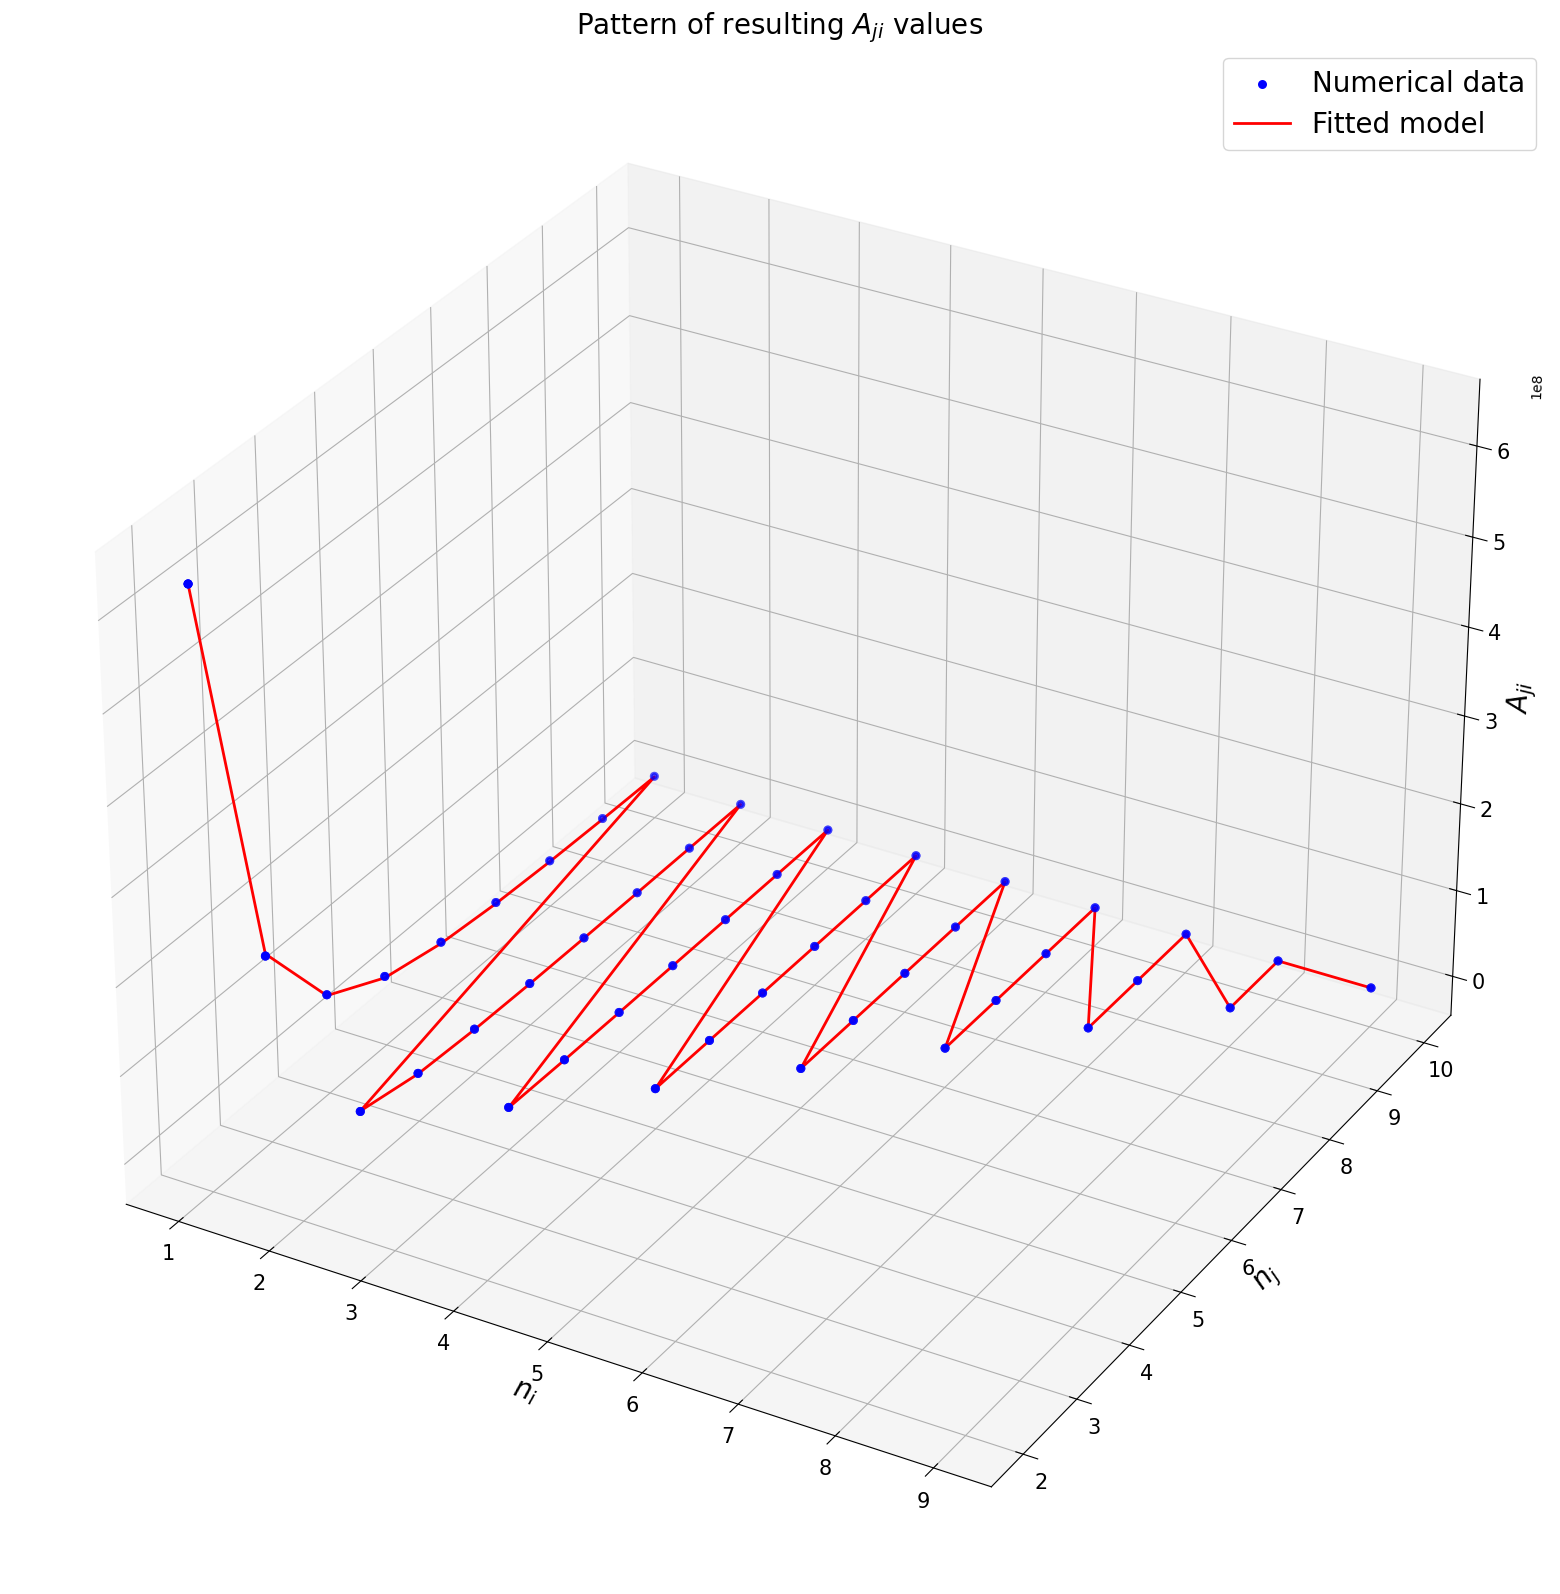

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Correctly initialize the figure and 3D axis object
fig = plt.figure(figsize=(24, 20))
ax = fig.add_subplot(projection='3d')

# Plot our numerical data/points
ax.scatter(n_i_vals, n_j_vals, A_ji_vals, color='b', linewidth=2, label='Numerical data')

# Plot our fitted function
fit_z = A_ji_fit((n_i_vals, n_j_vals), *popt)
ax.plot(n_i_vals, n_j_vals, fit_z, color='r', linewidth=2, label='Fitted model')

# Graph adjustments using Axes object methods
ax.set_title(r'Pattern of resulting $A_{ji}$ values', fontsize=20)
ax.set_xlabel(f'$n_i$', fontsize=20)
ax.set_ylabel(f'$n_j$', fontsize=20)
ax.set_zlabel(r'$A_{ji}$', fontsize=20)
ax.tick_params(axis='both', which='major', labelsize=15)
ax.legend(fontsize=20)

plt.show()

Fitting (in log space)

In [ ]:
from scipy.optimize import curve_fit
import numpy as np

# Define fitting function in log-log space
def ln_A_ji_fit(X, ln_C, alpha, beta):
    ln_ni, ln_nj = X
    return ln_C - alpha * ln_ni - beta * ln_nj

# Prepare log-transformed data
x = np.log(np.array(n_i_vals))
y = np.log(np.array(n_j_vals))
z = np.log(np.array(A_ji_vals))

# Perform 3D curve fitting on log-transformed variables
popt, pcov = curve_fit(ln_A_ji_fit, (x, y), z, p0=[np.log(6e8), 3, 3])

# Unpack parameters to print them
ln_C, alpha, beta = popt
C = np.exp(ln_C)

# Print optimized parameters [C, alpha, beta]
print("Optimized parameters [C, alpha, beta]:", [C, alpha, beta])

Optimized parameters [C, alpha, beta]: [np.float64(4221998655.214074), np.float64(2.6786223440687125), np.float64(3.013514569557586)]


Plotting (in log space)

*NOTE: Gemini was used to generate chunks of this code since I was not entirely sure how to do make a 2D log-log plot of this data myself

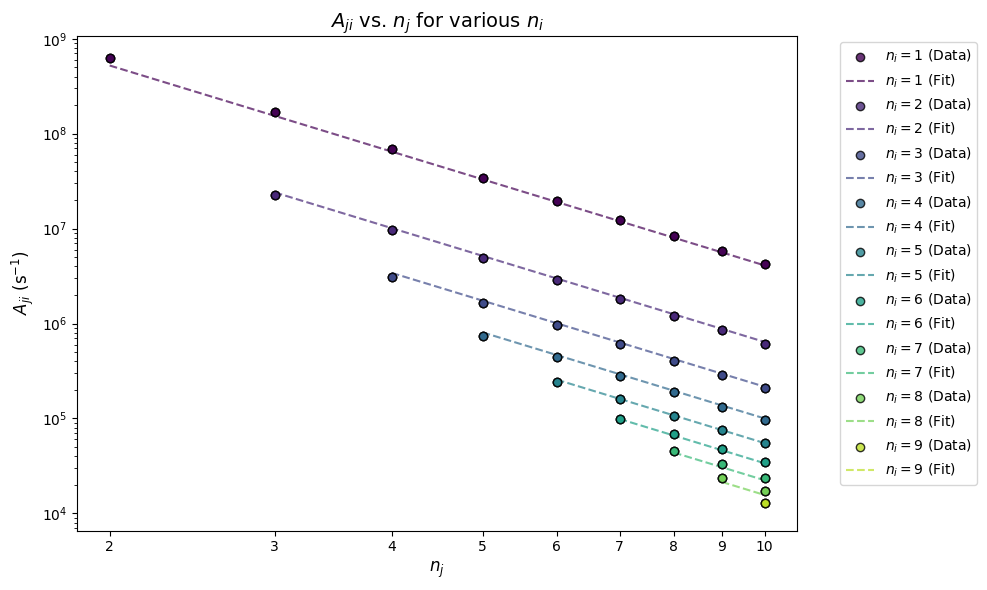

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Set up the figure
plt.figure(figsize=(10, 6))

# Unique values of n_i to group and plot
unique_ni = sorted(list(set(n_i_vals)))

# Use a colormap to distinguish different n_i states
colors = plt.cm.viridis(np.linspace(0, 0.9, len(unique_ni)))

for ni, color in zip(unique_ni, colors):
    # Extract data points matching this specific n_i
    mask = np.array(n_i_vals) == ni
    nj_subset = np.array(n_j_vals)[mask]
    A_subset = np.array(A_ji_vals)[mask]

    # Plot numerical data points
    plt.scatter(nj_subset, A_subset, color=color, alpha=0.8, edgecolor='k', zorder=3,
                label=f'$n_i = {ni}$ (Data)')

    # Generate a smooth fit line using [C, alpha, beta]
    nj_smooth = np.linspace(ni + 1, 10, 200)
    A_fit_smooth = C / (ni**alpha * nj_smooth**beta)

    # Plot fitted model (line)
    plt.plot(nj_smooth, A_fit_smooth, color=color, linestyle='--', alpha=0.7, zorder=2,
             label=f'$n_i = {ni}$ (Fit)')

# Configure log-log axes
plt.xscale('log')
plt.yscale('log')

# Add custom ticks
plt.xticks(ticks=range(2, 11), labels=range(2, 11))

# Labeling
plt.title(r'$A_{ji}$ vs. $n_j$ for various $n_i$', fontsize=14)
plt.xlabel(r'$n_j$', fontsize=12)
plt.ylabel(r'$A_{ji}$ (s$^{-1}$)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.tight_layout()

plt.show()

##Problem 3

slope, intercept: 34525.97141018174 1151.6946915611686
Gas temperature T (K): 2076261.11218214
Microturbulent velocity amplitude xi (km/s): 33.93662758084793


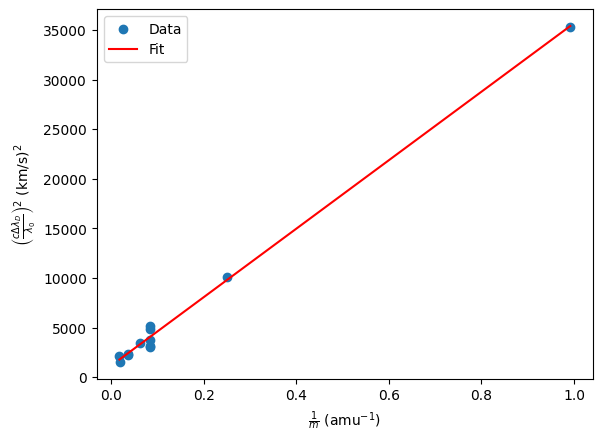

In [33]:
from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt

#Define any needed constant(s)
k_B = 1.380649e-23
c = 2.99792458e8

#Define linear fitting function
def linear_fit(y, m, b):
    y_fit = m * y + b
    return y_fit

#Define lambdas and FWHM from provided table
lambda_0_A = np.array([977, 1032, 1175, 1216, 1335, 1394, 1548, 1640, 1808, 1909, 2056, 2175])
FWHM_A = np.array([0.3898, 0.3355, 0.3647, 1.2696, 0.5181, 0.3747, 0.4711, 0.9163, 0.4731, 0.6477, 0.4461, 0.5537])

#Define masses (searched up on google) in order corresponding to above
mass_u = np.array([12.011, 15.999, 12.011, 1.008, 12.011, 28.085, 12.011, 4.003, 28.085, 12.011, 51.996, 55.845])

#Define y and x as rewritten (see my solution in the PDF)
dlam_D = FWHM_A / (2 * np.sqrt(np.log(2)))
y = (c * dlam_D / lambda_0_A)**2
x = 1 / mass_u

# Scale y to units of (km/s)^2 so all numbers are order 1 to 1e3 (idea from Claude)
y_kms = y / 1e6
popt, pcov = curve_fit(linear_fit, x, y_kms)
m, b = popt

# slope (in (km/s)^2 * amu) = 2 k_B T /  (1.66054e-27 * 1e6), convert to SI
T = m * 1e6 * 1.66054e-27 / (2 * k_B) # u to kg was found online
xi = np.sqrt(b)

print("slope, intercept:", m, b)
print("Gas temperature T (K):", T)
print("Microturbulent velocity amplitude xi (km/s):", xi)

#Plot data and fit line
plt.scatter(x, y_kms, label='Data')
x_fit = np.linspace(min(x), max(x), 100)
y_fit = linear_fit(x_fit, m, b)
plt.plot(x_fit, y_fit, color='red', label=f'Fit')
plt.xlabel(r'$\frac{1}{m}$ $(\text{amu}^{-1})$')
plt.ylabel(r'$\left(\frac{c\Delta \lambda_D}{\lambda_0}\right)^2$ $(\text{km}/\text{s})^2$')
plt.legend()
plt.show()


##Problem 4

Part c

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#Define constants and bounds for v and theta
c = 2.99792458e8
v_c = np.linspace(0.001, 0.9999, 2000)
theta = np.linspace(0, 2*np.pi, 1000)
v_c, theta = np.meshgrid(beta, theta, indexing='ij')

#Define V_mp and lambda_obs/lambda_0 functions
def V_mp(v, theta):
  numerator = v * np.sin(theta)
  numerator_physical = v * c * np.sin(theta)
  denominator = 1  + v*np.cos(theta)
  return numerator_physical / denominator / c

def lambda_obs_lambda_0(v, theta):
  numerator = 1 + (v)*np.cos(theta)
  denominator = np.sqrt(1-(v)**2)
  return numerator/denominator

Vpm = V_mp(v_c, theta)
lambmdaobs_lambda0 = lambda_obs_lambda_0(v_c, theta)

# One residual that is small only where both equations hold (idea from Claude)
resid = (Vpm - 2.52272)**2 + (lambmdaobs_lambda0 - 0.343035)**2
i, j = np.unravel_index(np.argmin(resid), resid.shape)

# Print with scalar values accessed using the resolved [i, j] coordinates
print(f"v/c = {v_c[i, j]:.4f}, theta = {np.degrees(theta[i, j]):.2f} deg ({theta[i,j]:.4f} radians)")

v/c = 0.9299, theta = 160.00 deg (2.7925 radians)
